# Import Library

In [ ]:
!pip install category_encoders

In [ ]:
# Processing & Visualization Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import Data
from google.colab import drive

# Encoding Data
import category_encoders as ce
from sklearn.preprocessing import LabelEncoder

# Normalize Data
from sklearn.preprocessing import StandardScaler

# Data Splitting
from sklearn.model_selection import train_test_split

#Over Sampling Data
from imblearn.over_sampling import SMOTE

# Modeling Algorithm
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Evaluation Matrics
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc
from sklearn.model_selection import GridSearchCV

# Import Dataset

Source Data
* Kaggle: https://www.kaggle.com/code/farazrahman/telco-customer-churn-logisticregression?select=WA_Fn-UseC_-Telco-Customer-Churn.csv

In [ ]:
# Connect Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Import Dataset
df = pd.read_csv('/content/drive/MyDrive/Dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Data Preprocessing

In [ ]:
# Data Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# Data Descriptive
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
# Checking Missing Value
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
# Check Duplicated Data
df.duplicated().sum()

np.int64(0)

# EDA

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


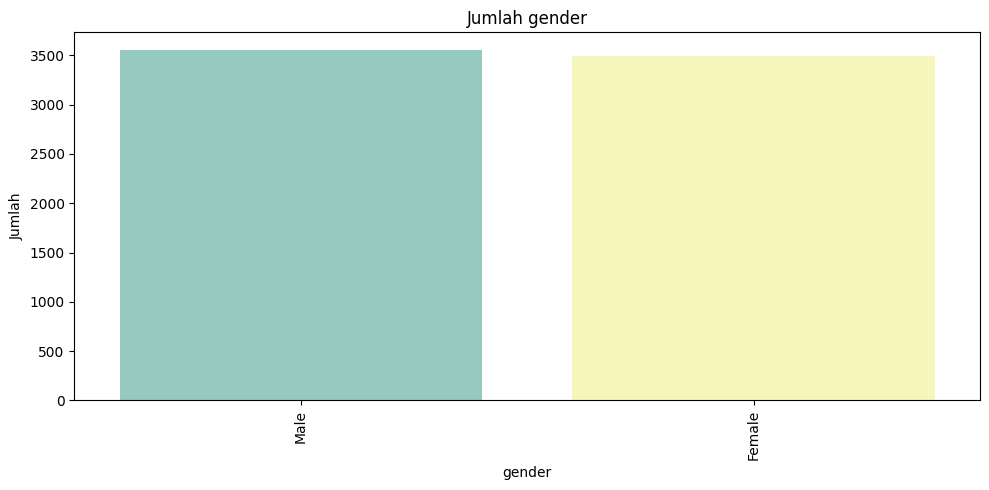

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


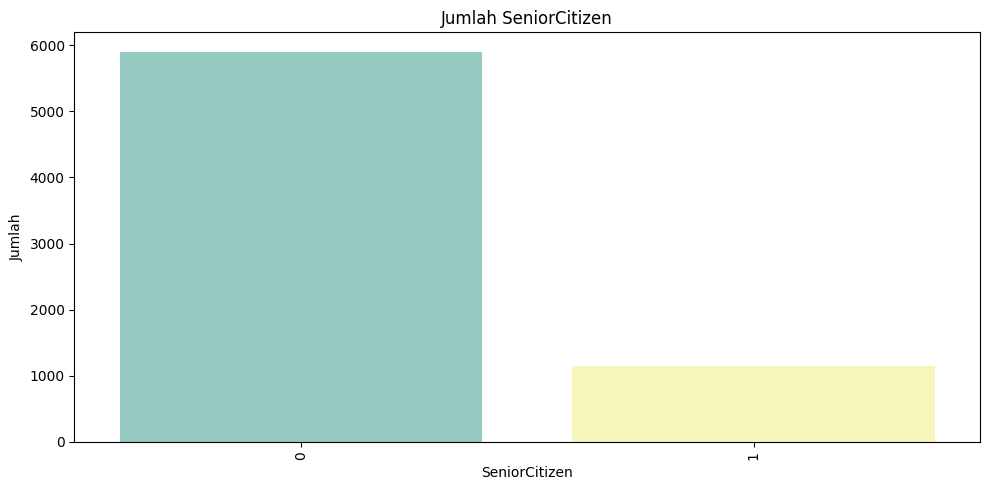

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


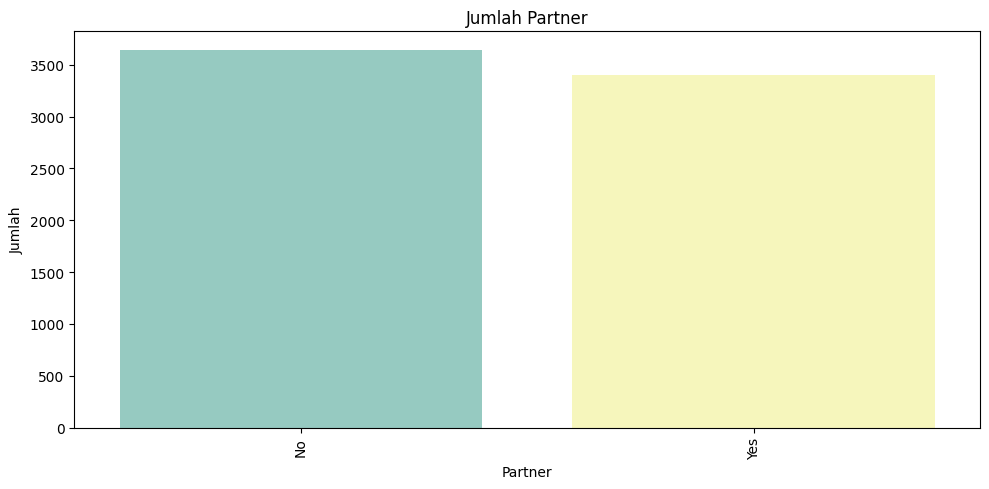

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


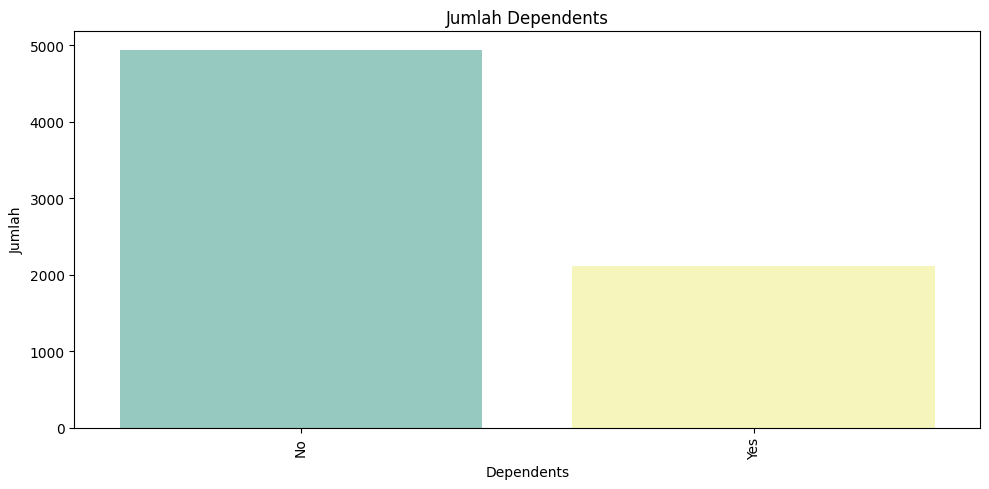

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


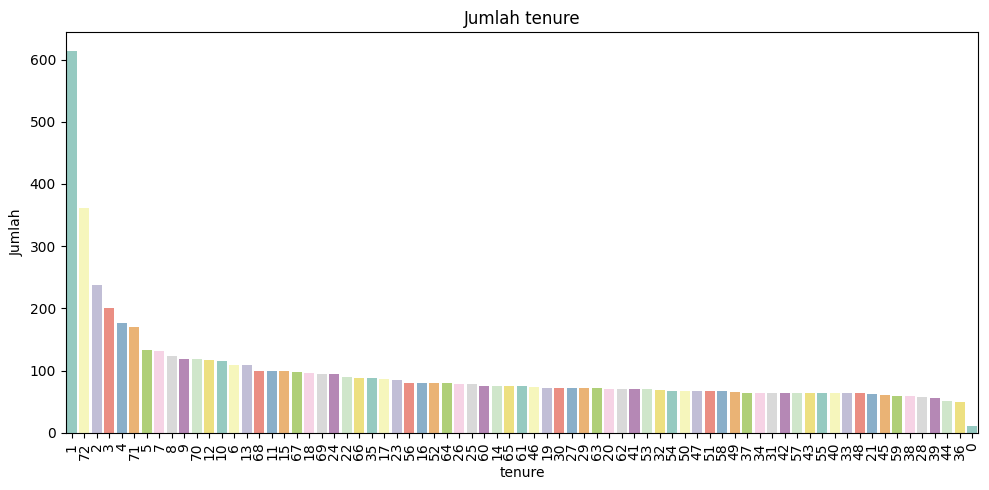

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


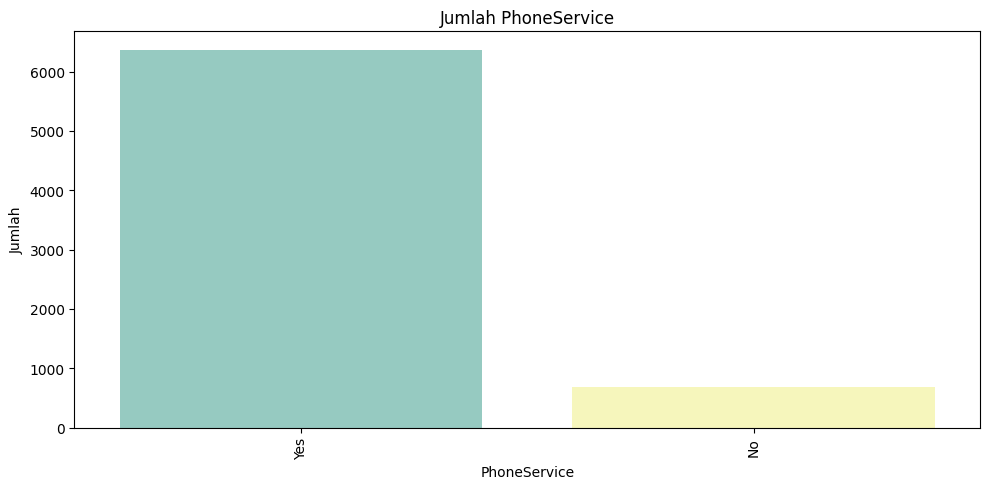

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


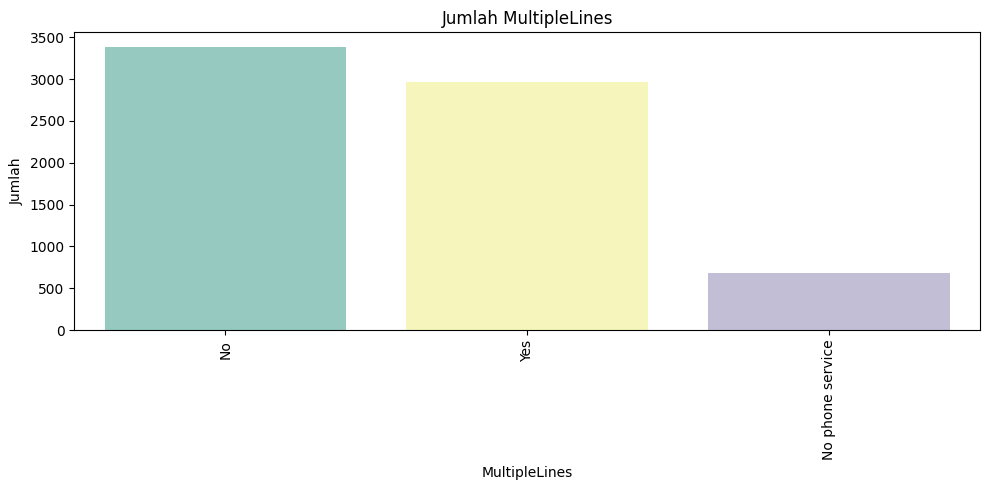

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


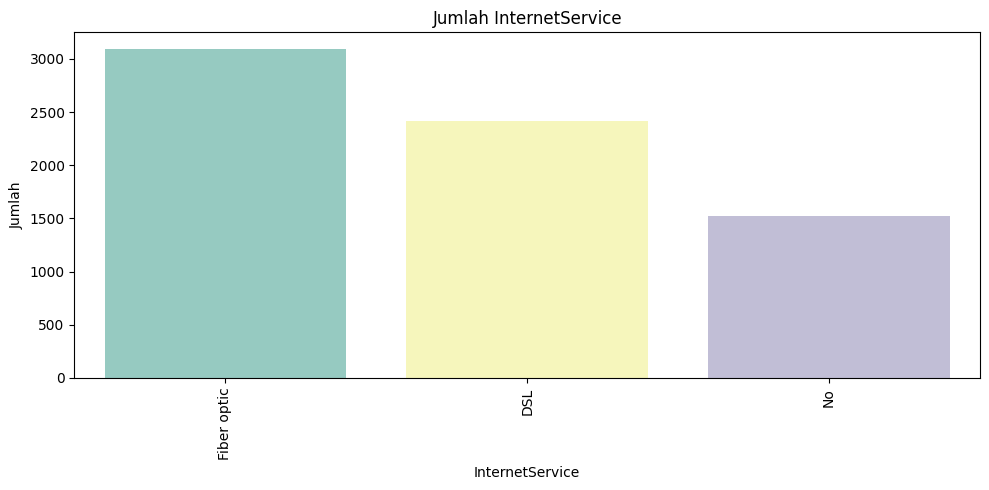

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


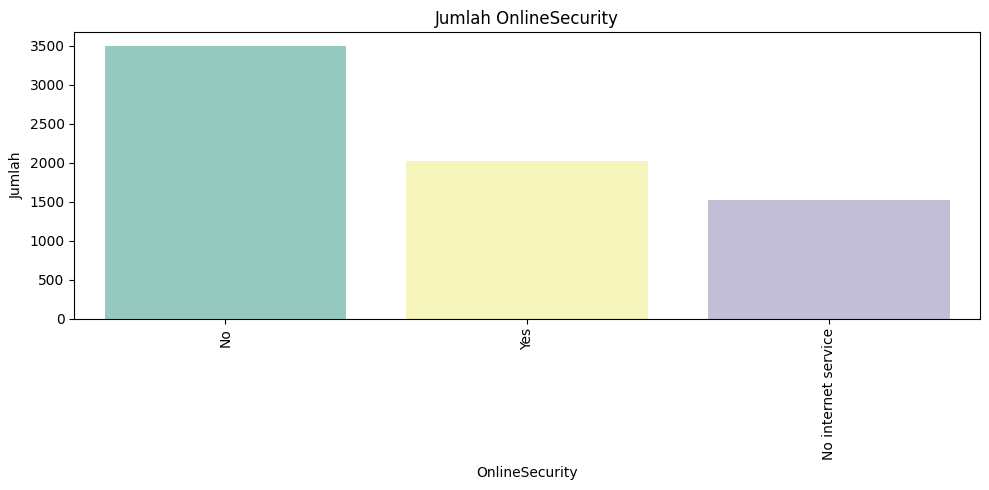

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


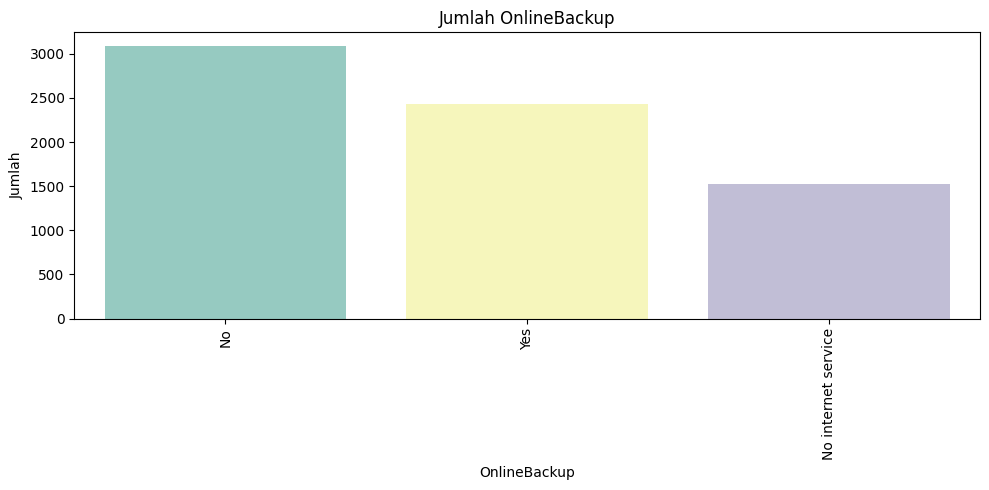

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


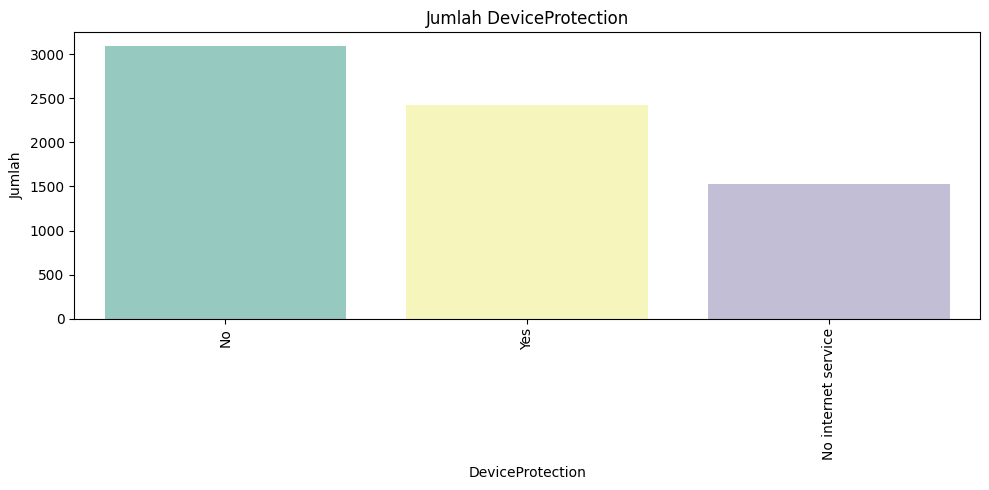

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


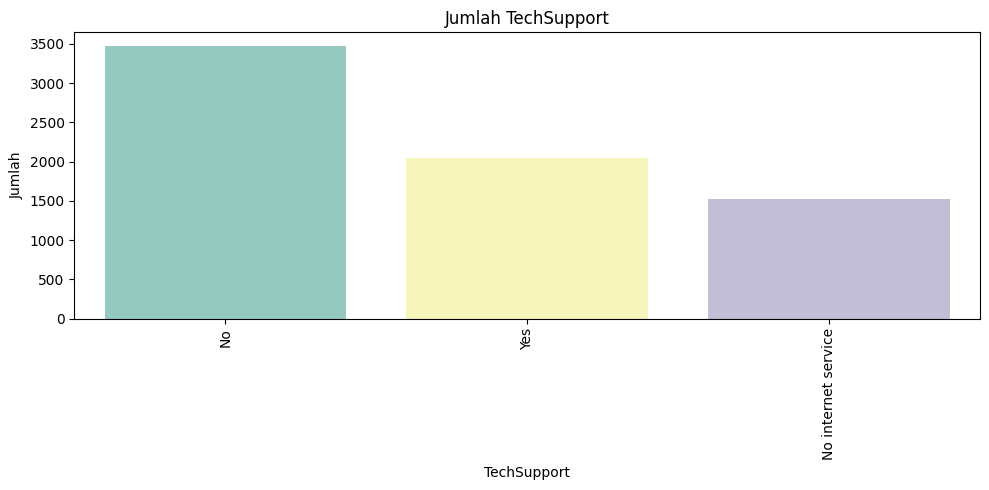

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


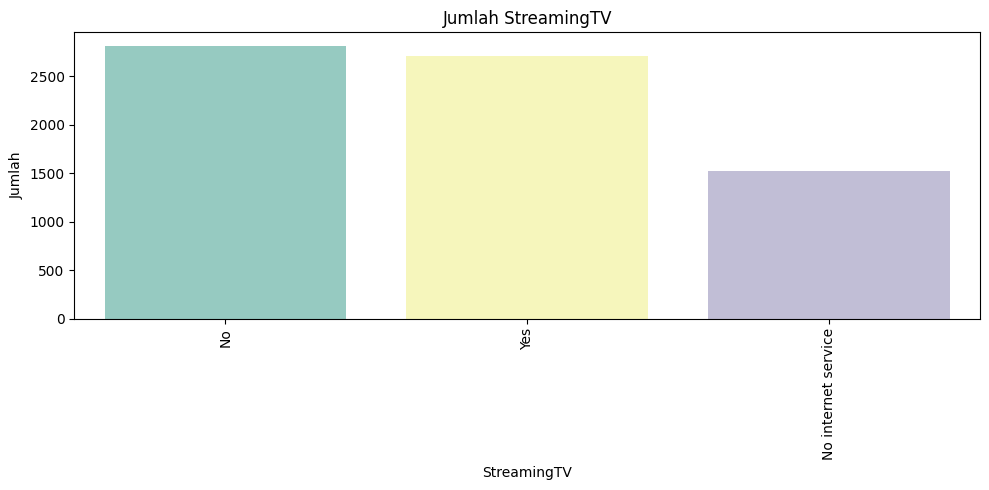

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


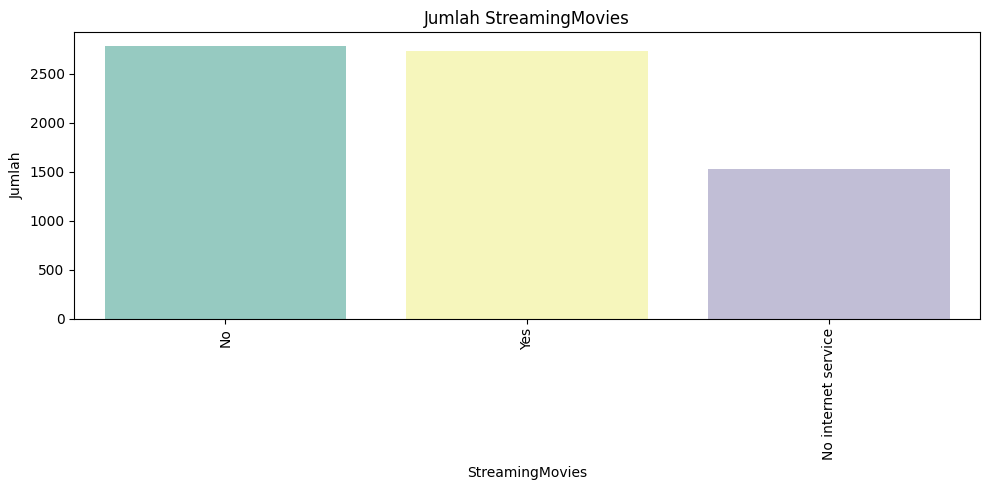

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


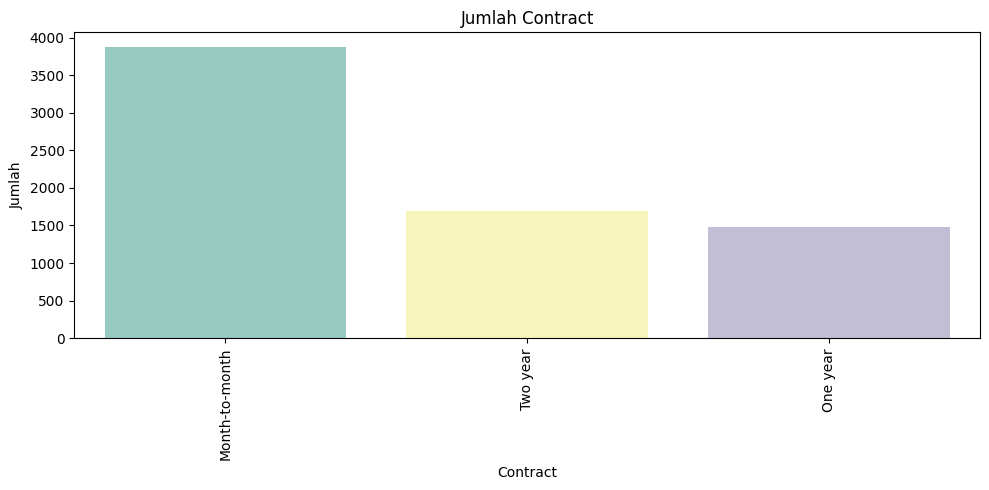

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


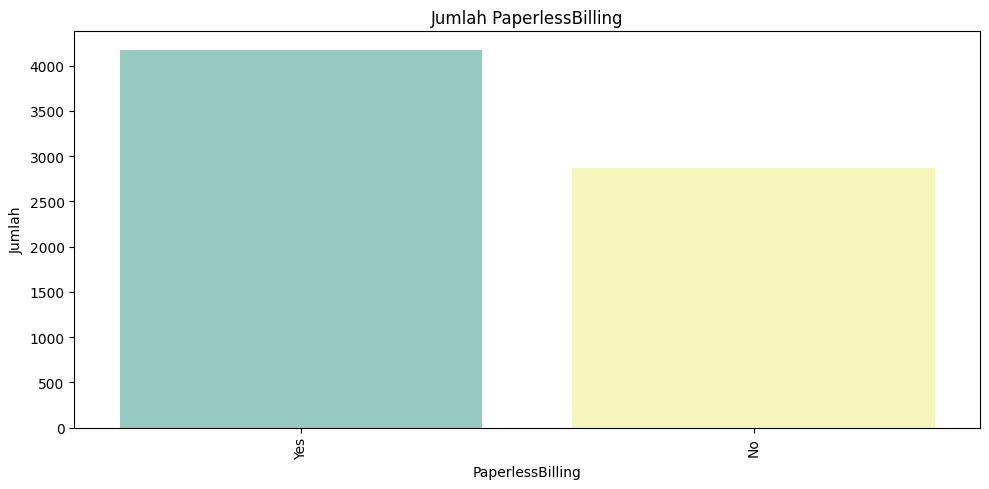

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


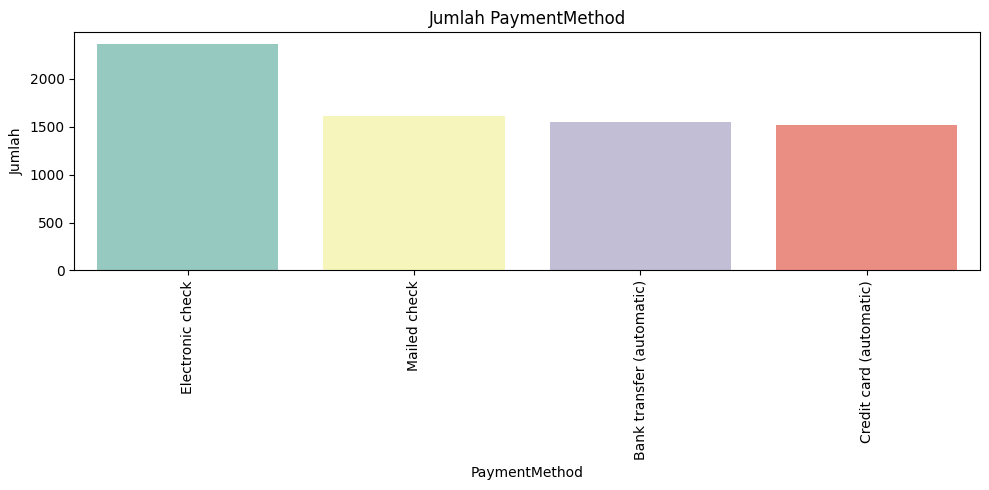

/tmp/ipykernel_11979/1375316103.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)


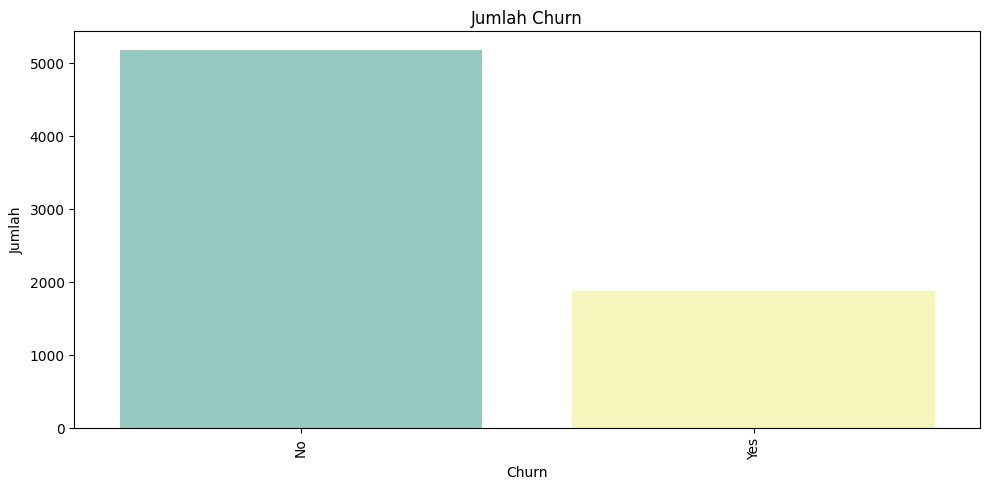

In [ ]:
# Displaying the distribution of data for each variable
excuse = ['customerID', 'MonthlyCharges', 'TotalCharges']

for i in df.columns:

  if i not in excuse:

    plt.figure(figsize = (10,5))

    sns.countplot(x=i, data=df, palette='Set3', order=df[i].value_counts().index)

    plt.title('Jumlah {}'.format(i))

    plt.xlabel(i)

    plt.ylabel('Jumlah')

    plt.xticks(rotation=90)

    plt.tight_layout()

    plt.show()

In [ ]:
# Ubah spasi kosong menjadi NaN, lalu ubah tipe data menjadi float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Isi nilai kosong (NaN) dengan 0 (karena mereka pelanggan baru dengan tenure=0)
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


# Encoding

In [ ]:
# Churn Labeling
le = LabelEncoder()

df['Churn'] = le.fit_transform(df['Churn'])

In [ ]:
# Payment Labeling
encoder = ce.BinaryEncoder(cols=['PaymentMethod'])

df = encoder.fit_transform(df)

In [ ]:
# Contract labeling
contract_mapping = {'Month-to-month': 0, 'One year': 1, 'Two year': 2}

df['Contract'] = df['Contract'].map(contract_mapping)

In [ ]:
# One-Hot Encoding
df = pd.get_dummies(df, drop_first=True, dtype=int)

df.head(5)

,SeniorCitizen,tenure,Contract,PaymentMethod_0,PaymentMethod_1,PaymentMethod_2,MonthlyCharges,TotalCharges,Churn,customerID_0003-MKNFE,...,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_Yes
0,0,1,0,0,0,1,29.85,29.85,0,0,...,1,0,0,0,0,0,0,0,0,1
1,0,34,1,0,1,0,56.95,1889.50,0,0,...,0,0,1,0,0,0,0,0,0,0
2,0,2,0,0,1,0,53.85,108.15,1,0,...,1,0,0,0,0,0,0,0,0,1
3,0,45,1,0,1,1,42.30,1840.75,0,0,...,0,0,1,0,1,0,0,0,0,0
4,0,2,0,0,0,1,70.70,151.65,1,0,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
df.select_dtypes(include=['number']).columns.tolist()

['SeniorCitizen',
 'tenure',
 'Contract',
 'PaymentMethod_0',
 'PaymentMethod_1',
 'PaymentMethod_2',
 'MonthlyCharges',
 'TotalCharges',
 'Churn',
 'customerID_0003-MKNFE',
 'customerID_0004-TLHLJ',
 'customerID_0011-IGKFF',
 'customerID_0013-EXCHZ',
 'customerID_0013-MHZWF',
 'customerID_0013-SMEOE',
 'customerID_0014-BMAQU',
 'customerID_0015-UOCOJ',
 'customerID_0016-QLJIS',
 'customerID_0017-DINOC',
 'customerID_0017-IUDMW',
 'customerID_0018-NYROU',
 'customerID_0019-EFAEP',
 'customerID_0019-GFNTW',
 'customerID_0020-INWCK',
 'customerID_0020-JDNXP',
 'customerID_0021-IKXGC',
 'customerID_0022-TCJCI',
 'customerID_0023-HGHWL',
 'customerID_0023-UYUPN',
 'customerID_0023-XUOPT',
 'customerID_0027-KWYKW',
 'customerID_0030-FNXPP',
 'customerID_0031-PVLZI',
 'customerID_0032-PGELS',
 'customerID_0036-IHMOT',
 'customerID_0040-HALCW',
 'customerID_0042-JVWOJ',
 'customerID_0042-RLHYP',
 'customerID_0048-LUMLS',
 'customerID_0048-PIHNL',
 'customerID_0052-DCKON',
 'customerID_0052-YN

In [ ]:
# separate features(X) and target(Y)
X = df.drop('Churn', axis=1)

y = df['Churn']


# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Normalization
scaler = StandardScaler()

target_scaler = ['tenure', 'MonthlyCharges', 'TotalCharges']

X_train[target_scaler] = scaler.fit_transform(X_train[target_scaler])

X_test[target_scaler] = scaler.transform(X_test[target_scaler])


# Oversampling
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

In [ ]:
# Data Checking Before Oversamling
print("Before OverSampling count of yes: {}".format(sum(y_train==1)))
print("Before OverSampling count of no: {} \n".format(sum(y_train==0)))

# Data Checking After Oversampling
print("After OverSampling count of yes: {}".format(sum(y_train_resampled==1)))
print("After OverSampling count of no: {}".format(sum(y_train_resampled==0)))

Before OverSampling count of yes: 1496
Before OverSampling count of no: 4138 

After OverSampling count of yes: 4138
After OverSampling count of no: 4138


# Modeling

## Fitting Model

In [ ]:
# Fitting Model Logistic Regression
lr = LogisticRegression()

lr.fit(X_train_resampled, y_train_resampled)


# Fitting Model Random Forest
rf = RandomForestClassifier()

rf.fit(X_train_resampled, y_train_resampled)


# Fitting Model XGBoost
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

xgb.fit(X_train_resampled, y_train_resampled)


# Fitting Model LightGBM
lgb = LGBMClassifier(random_state=42)

lgb.fit(X_train_resampled, y_train_resampled)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:24:02] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 4138, number of negative: 4138
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001850 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 818
[LightGBM] [Info] Number of data points in the train set: 8276, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


LGBMClassifier(random_state=42)

# Evaluasi

In [ ]:
# Logistic Evaluation
y_pred = lr.predict(X_test)

print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred))

print("ROC AUC:", roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]))

[[764 272]
 [ 74 299]]
              precision    recall  f1-score   support

           0       0.91      0.74      0.82      1036
           1       0.52      0.80      0.63       373

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.77      1409

ROC AUC: 0.8469844317699546


In [ ]:
# Random Forest Evaluation
y_pred = rf.predict(X_test)

print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred))

print("ROC AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))

[[782 254]
 [ 73 300]]
              precision    recall  f1-score   support

           0       0.91      0.75      0.83      1036
           1       0.54      0.80      0.65       373

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.82      0.77      0.78      1409

ROC AUC: 0.8397256409990994


In [ ]:
# XGB Evaluation
y_pred_xgb = xgb.predict(X_test)

print(confusion_matrix(y_test, y_pred_xgb))

print(classification_report(y_test, y_pred_xgb))

print("ROC AUC:", roc_auc_score(y_test, xgb.predict_proba(X_test)[:, 1]))

[[855 181]
 [122 251]]
              precision    recall  f1-score   support

           0       0.88      0.83      0.85      1036
           1       0.58      0.67      0.62       373

    accuracy                           0.78      1409
   macro avg       0.73      0.75      0.74      1409
weighted avg       0.80      0.78      0.79      1409

ROC AUC: 0.8283690622832713


In [ ]:
# LGB Evaluation
y_pred_lgb = lgb.predict(X_test)

print(confusion_matrix(y_test, y_pred_lgb))

print(classification_report(y_test, y_pred_lgb))

print("ROC AUC:", roc_auc_score(y_test, lgb.predict_proba(X_test)[:, 1]))

[[844 192]
 [100 273]]
              precision    recall  f1-score   support

           0       0.89      0.81      0.85      1036
           1       0.59      0.73      0.65       373

    accuracy                           0.79      1409
   macro avg       0.74      0.77      0.75      1409
weighted avg       0.81      0.79      0.80      1409

ROC AUC: 0.8439515252517933


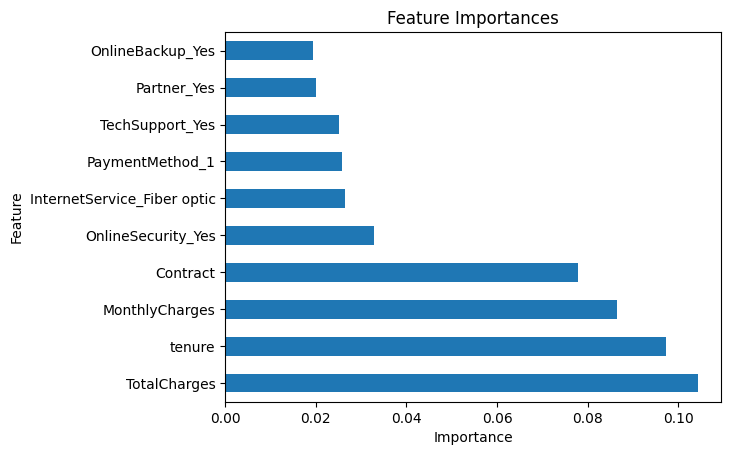

In [ ]:
# Feature Importances (Random Forest)
feature_importances = pd.Series(rf.feature_importances_, index=X.columns)

feature_importances.nlargest(10).plot(kind='barh')

plt.title('Feature Importances')

plt.xlabel('Importance')

plt.ylabel('Feature')

plt.show()

### 🔑 Analisis dan Interpretasi Feature Importances

Grafik di atas menunjukkan tingkat kepentingan fitur (*Feature Importances*) dari model dalam memprediksi apakah seorang pelanggan akan *Churn* atau tidak. Semakin panjang batang horizontalnya, semakin besar kontribusi fitur tersebut terhadap keputusan prediksi model.

Berikut adalah poin-poin penting dan interpretasi bisnis dari hasil tersebut:

#### 1. Tiga Fitur Utama yang Paling Mendominasi
Model sangat bergantung pada tiga faktor finansial dan loyalitas utama berikut untuk mendeteksi *churn*:
* **TotalCharges (Skor Tertinggi ~0.104):** Total biaya yang sudah dibayarkan oleh pelanggan menjadi indikator terkuat. Perubahan atau akumulasi biaya yang besar sangat memengaruhi keputusan pelanggan untuk bertahan atau pergi.
* **tenure (Skor ~0.098):** Durasi berapa lama pelanggan telah berlangganan berada di posisi kedua. Hal ini logis, karena pelanggan baru biasanya memiliki risiko *churn* yang lebih tinggi dibandingkan pelanggan lama yang sudah loyal.
* **MonthlyCharges (Skor ~0.086):** Biaya bulanan yang ditagihkan menduduki posisi ketiga. Biaya bulanan yang terlalu mahal sering kali menjadi pemicu utama pelanggan mencari kompetitor lain.

#### 2. Pengaruh Kontrak dan Layanan Tambahan
* **Contract (Skor ~0.078):** Jenis kontrak (apakah bulanan, 1 tahun, atau 2 tahun) memegang peran krusial berikutnya. Pelanggan dengan kontrak jangka pendek (*Month-to-month*) umumnya jauh lebih mudah untuk *churn*.
* **OnlineSecurity_Yes (Skor ~0.033):** Memiliki layanan keamanan online terbukti memberikan dampak signifikan pada retensi pelanggan dibandingkan fitur layanan tambahan lainnya.

#### 3. Faktor Pendukung Lainnya
Fitur-fitur seperti *InternetService_Fiber optic, PaymentMethod_1, TechSupport_Yes, Partner_Yes,* dan *OnlineBackup_Yes* memiliki tingkat kepentingan yang lebih rendah (di bawah 0.03), namun tetap memberikan kontribusi tambahan bagi model untuk memperhalus akurasi prediksinya.

#### 💡 Wawasan Bisnis (Actionable Insights)
Berdasarkan hasil ini, strategi tim manajemen untuk menekan angka *churn* sebaiknya difokuskan pada:
1. **Intervensi Finansial:** Memberikan perhatian khusus atau promo retensi kepada pelanggan yang memiliki kombinasi `MonthlyCharges` tinggi namun `tenure` masih rendah (pelanggan baru dengan biaya mahal).
2. **Edukasi Kontrak:** Mendorong pelanggan kontrak bulanan (`Contract`) untuk beralih ke kontrak jangka panjang (1 atau 2 tahun) melalui diskon khusus, karena jenis kontrak merupakan penentu besar dalam stabilitas retensi.
3. **Optimasi Layanan:** Meningkatkan penjualan/bundling layanan tambahan yang krusial seperti `OnlineSecurity` dan `TechSupport` untuk meningkatkan keterikatan pelanggan terhadap produk.


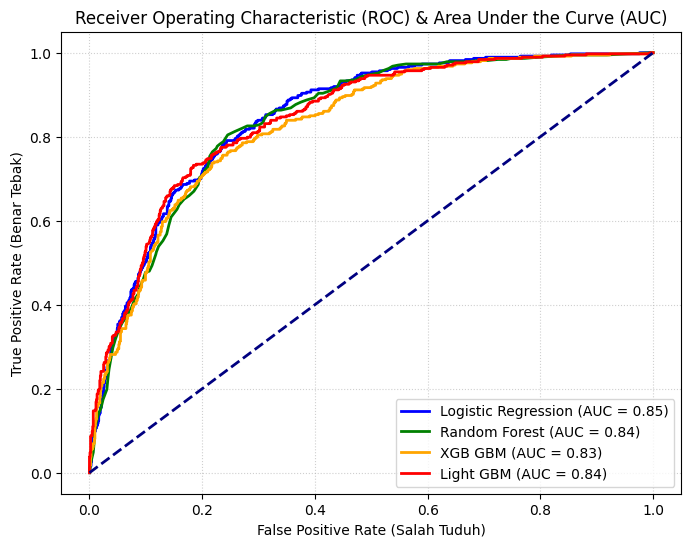

In [ ]:
# Probability predictions for each model
y_pred_proba_lr = lr.predict_proba(X_test)[:, 1]

y_pred_proba_rf = rf.predict_proba(X_test)[:, 1]

y_pred_proba_xgb = xgb.predict_proba(X_test)[:, 1]

y_pred_proba_lgb = lgb.predict_proba(X_test)[:, 1]



# Calculate FPR and TPR for the ROC curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)

fpr_lgb, tpr_lgb, _ = roc_curve(y_test, y_pred_proba_lgb)



# Calculate the AUC score for each model
roc_auc_lr = auc(fpr_lr, tpr_lr)

roc_auc_rf = auc(fpr_rf, tpr_rf)

roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

roc_auc_lgb = auc(fpr_lgb, tpr_lgb)


# Single ROC-AUC Curve Plot
plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, color='blue', lw=2, label=f'Logistic Regression (AUC = {roc_auc_lr:.2f})')

plt.plot(fpr_rf, tpr_rf, color='green', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.2f})')

plt.plot(fpr_xgb, tpr_xgb, color='orange', lw=2, label=f'XGB GBM (AUC = {roc_auc_xgb:.2f})')

plt.plot(fpr_lgb, tpr_lgb, color='red', lw=2, label=f'Light GBM (AUC = {roc_auc_lgb:.2f})')


# Diagonal line representing random guessing (baseline)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')


# Completeness of the graph
plt.xlabel('False Positive Rate (Salah Tuduh)')

plt.ylabel('True Positive Rate (Benar Tebak)')

plt.title('Receiver Operating Characteristic (ROC) & Area Under the Curve (AUC)')

plt.legend(loc='lower right')

plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

### 📊 Analisis dan Interpretasi Kurva ROC-AUC

Berdasarkan grafik kurva ROC-AUC yang dihasilkan, berikut adalah interpretasi detail mengenai performa dari keempat model yang telah dilatih (*Logistic Regression, Random Forest, XGBoost,* dan *LightGBM*):

#### 1. Performa Model Terbaik
* **Logistic Regression** keluar sebagai model terbaik dengan nilai **AUC tertinggi sebesar 0.85**.
* Nilai ini menunjukkan bahwa model Logistic Regression memiliki probabilitas **85%** untuk membedakan dengan benar antara pelanggan yang akan *Churn* (keluar) dan pelanggan yang akan tetap berlangganan (*Retain*).

#### 2. Perbandingan Skor AUC Seluruh Model
Secara keseluruhan, keempat model menunjukkan performa yang **sangat baik** (rentang nilai AUC 0.83 - 0.85). Berikut adalah urutan performanya:
1. **Logistic Regression (AUC = 0.85)** 🏆 *(Terbaik)*
2. **Random Forest (AUC = 0.84)**
3. **Light GBM (AUC = 0.84)**
4. **XGB GBM (AUC = 0.83)**

#### 3. Cara Membaca Grafik secara Visual
* **Kelengkungan Kurva:** Semakin kurva melengkung mendekati sudut kiri atas (titik koordinat 0.0 pada sumbu X dan 1.0 pada sumbu Y), maka performa model semakin sempurna. Kurva **Logistic Regression (garis biru)** terlihat berada sedikit lebih tinggi dan dominan dibandingkan model lainnya di sebagian besar area.
* **Garis Diagonal Putus-putus:** Garis ini merupakan *baseline* (tebakan acak/koin dengan AUC = 0.50). Karena seluruh kurva model melengkung jauh ke atas meninggalkan garis baseline ini, artinya kombinasi proses pra-pemrosesan data (seperti *StandardScaler* dan *SMOTE Oversampling*) yang telah dilakukan sebelumnya berhasil membantu model belajar secara optimal.

#### 💡 Kesimpulan Rekomendasi
Untuk tahapan selanjutnya atau deployment, model **Logistic Regression** sangat direkomendasikan karena:
1. Menghasilkan skor akurasi pemisahan kelas tertinggi (AUC = 0.85).
2. Memiliki beban komputasi yang jauh lebih ringan dibandingkan model *ensemble* (RF, XGB, LGBM).
3. Karakteristik modelnya linear, sehingga koefisien fiturnya jauh lebih mudah diinterpretasikan untuk kebutuhan bisnis (mencari tahu faktor apa yang paling memicu pelanggan untuk *churn*).
